# HS4002 Week 9

## Principal components analysis

A principal component is a linear combination of the variables. PCA reduces them to a smaller number of uncorrelated components.

The worked example uses five GSS variables: income, occupational prestige, education, number of children, and age. Each is scaled to mean 0 and SD 1. We fit the model with `sklearn.decomposition.PCA` and draw the scree plot with `plotnine`.


In [2]:
!pip install pandas numpy plotnine scikit-learn statsmodels

import pandas as pd
import numpy as np
from plotnine import *
import warnings
warnings.filterwarnings('ignore')



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
raw_df = pd.read_csv("gss2022_mini2.csv")

chosen_variables = [
	'id', 'age', 'happy', 'yrlvmus', 'yrartxbt', 'yrmovie', 'yrcreat',
	'income16', 'prestg10', 'degree', 'biokids', 'educ'
]
df = raw_df[chosen_variables].copy()

income_map = {
	1: 500,    2: 2000,   3: 3500,   4: 4500,   5: 5500,   6: 6500,
	7: 7500,   8: 9000,   9: 11250,  10: 13750, 11: 16250, 12: 18750,
	13: 21250, 14: 23750, 15: 27500, 16: 32500, 17: 37500, 18: 45000,
	19: 55000, 20: 67500, 21: 82500, 22: 100000, 23: 120000, 24: 140000,
	25: 160000, 26: 250000
}
df['income_cont'] = df['income16'].map(income_map)

df['binary_lvmus']  = (df['yrlvmus']  == 1).astype(int)
df['binary_artxbt'] = (df['yrartxbt'] == 1).astype(int)
df['binary_movie']  = (df['yrmovie']  == 1).astype(int)
df['binary_creat']  = (df['yrcreat']  == 1).astype(int)
df['ba_binary']     = (df['degree'] >= 3).astype(int)
df['happy_bin']     = (df['happy'] <= 2).astype(int)


# Steps

1. Choose the variables.
2. Scale each one to mean 0 and SD 1.
3. Fit the PCA.
4. Decide how many components to keep. The scree plot is the guide. There is no single rule.
5. Read the loadings.
6. Use the components in a plot or a regression.


## 1. Choose the variables

`income_cont` is income in dollars. `prestg10` is occupational prestige. `educ` is years of schooling. `biokids` is the number of children. `age` is age in years.


In [4]:
cols = ["income_cont", "prestg10", "educ", "biokids", "age"]
work = df.dropna(subset=cols).copy()
work[cols].describe().round(1)


,income_cont,prestg10,educ,biokids,age
count,1056.0,1056.0,1056.0,1056.0,1056.0
mean,86222.1,46.8,14.9,1.6,50.9
std,72378.7,13.3,2.7,1.5,17.3
min,500.0,17.0,2.0,0.0,18.0
25%,32500.0,36.0,13.0,0.0,36.0
50%,67500.0,47.0,15.0,2.0,51.0
75%,120000.0,59.0,16.0,2.0,66.0
max,250000.0,80.0,20.0,11.0,89.0


## 2--3. Scale, then fit

`StandardScaler` subtracts the mean and divides by the standard deviation. Without that step, income, which is measured in dollars, would dominate the first component.


In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = StandardScaler().fit_transform(work[cols])
pca = PCA().fit(X)

prop = pca.explained_variance_ratio_
print(pd.DataFrame({
    "Standard deviation": pca.explained_variance_ ** 0.5,
    "Proportion of variance": prop,
    "Cumulative proportion": prop.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5"]).T.round(3))


                          PC1    PC2    PC3    PC4    PC5
Standard deviation      1.368  1.127  0.882  0.781  0.689
Proportion of variance  0.374  0.254  0.155  0.122  0.095
Cumulative proportion   0.374  0.628  0.783  0.905  1.000


In [6]:
X

array([[ 0.1904493 , -0.58890628,  0.4275905 , -0.38187366,  1.22221802],
       [ 0.1904493 , -0.96439537,  0.4275905 , -1.03334148, -1.60982932],
       [-0.81170187, -0.6640041 , -0.31998494,  0.26959416,  0.64424917],
       ...,
       [-0.43157556,  1.96441954,  0.4275905 ,  1.57252981,  1.56899932],
       [ 1.01981578,  1.06324572,  0.80137822, -1.03334148, -0.10711032],
       [ 0.1904493 , -0.36361283,  1.92274139, -0.38187366, -0.04931344]],
      shape=(1056, 5))

PC1 accounts for 37.4 per cent of the variance. The first two components together account for 62.8 per cent.


## 4. Loadings

In `sklearn`, each row of `pca.components_` is one component. Transposing it puts the variables in the rows, so each column is a component. A large loading means that variable defines that component.


In [7]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"],
)
print(loadings.round(3))


               PC1    PC2    PC3    PC4    PC5
income_cont  0.524  0.009 -0.517  0.676 -0.030
prestg10     0.592  0.095  0.042 -0.457 -0.656
educ         0.594 -0.112  0.209 -0.268  0.721
biokids     -0.098  0.710 -0.560 -0.351  0.223
age          0.109  0.689  0.612  0.373 -0.022


How would you describe PC1 and PC2?

PC1 loads on income, occupational prestige, and education. It focuses on SES. It tells me that people with high PC1 score have higher income also, higher occupational prestige and higher education. 

PC2 loads on number of children and age. It focuses on life stage. It tells me that people with high PC2 score tend to be older and have more children. 

PC1 and PC2 are split and are uncorrelated because of the anture of PCA. This means SES and life stage will appear as two separate dimensions so that we can explain things more clearly because SES has nothing to do with life stage. 


## 5. How many components?

Look for an elbow in the scree plot: the point where adding another component buys little extra variance.


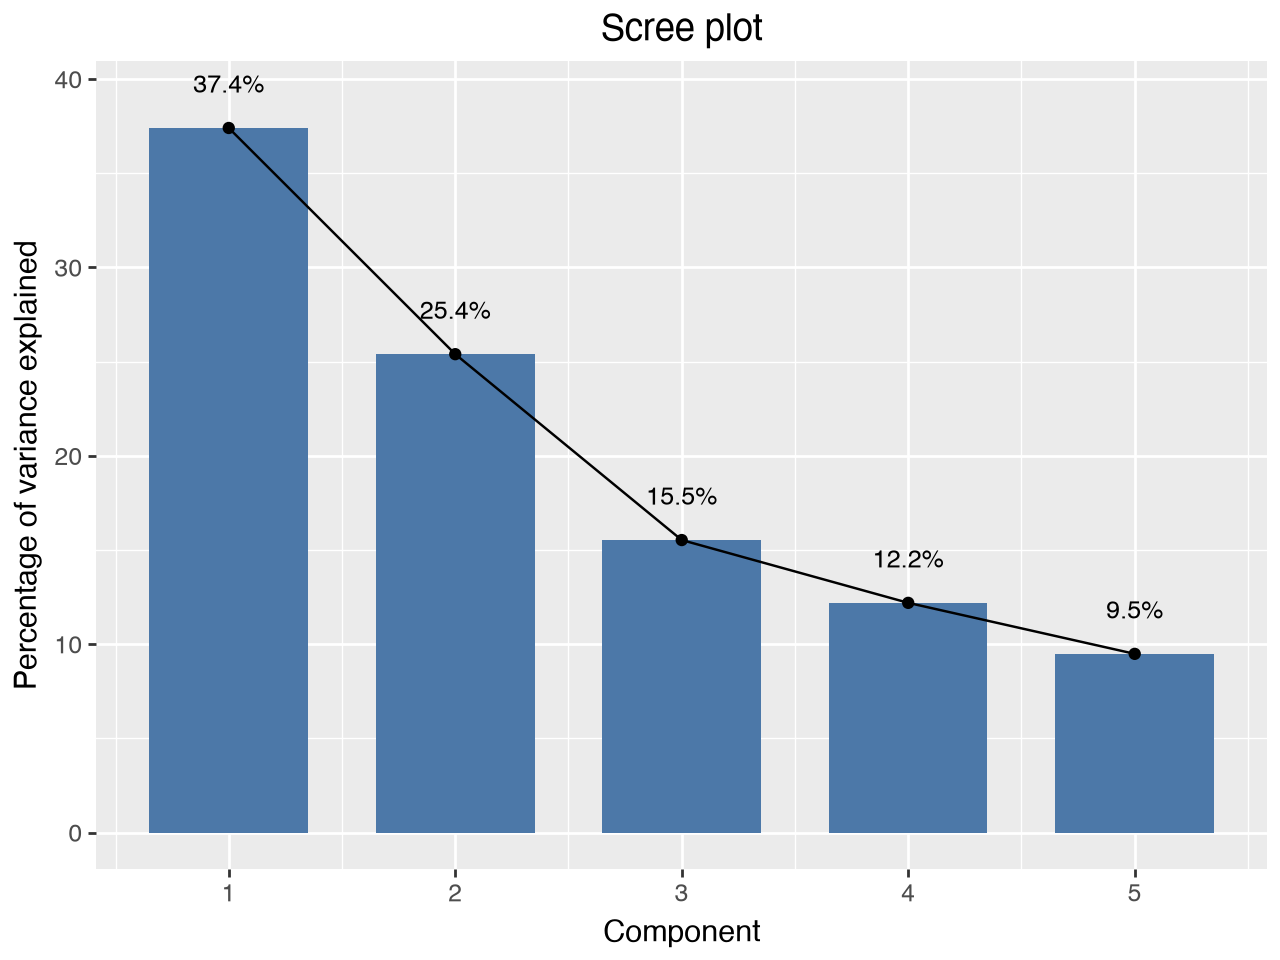

In [8]:
scree = pd.DataFrame({
    "component": range(1, 6),
    "percent": pca.explained_variance_ratio_ * 100,
})
scree["label"] = scree["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained", title="Scree plot")
)


## 6. Use the components

The first two components locate each person in a plane. Colour the points by whether the person has a BA. A BA was not one of the five variables in the PCA, so the colour is a separate fact about the person.


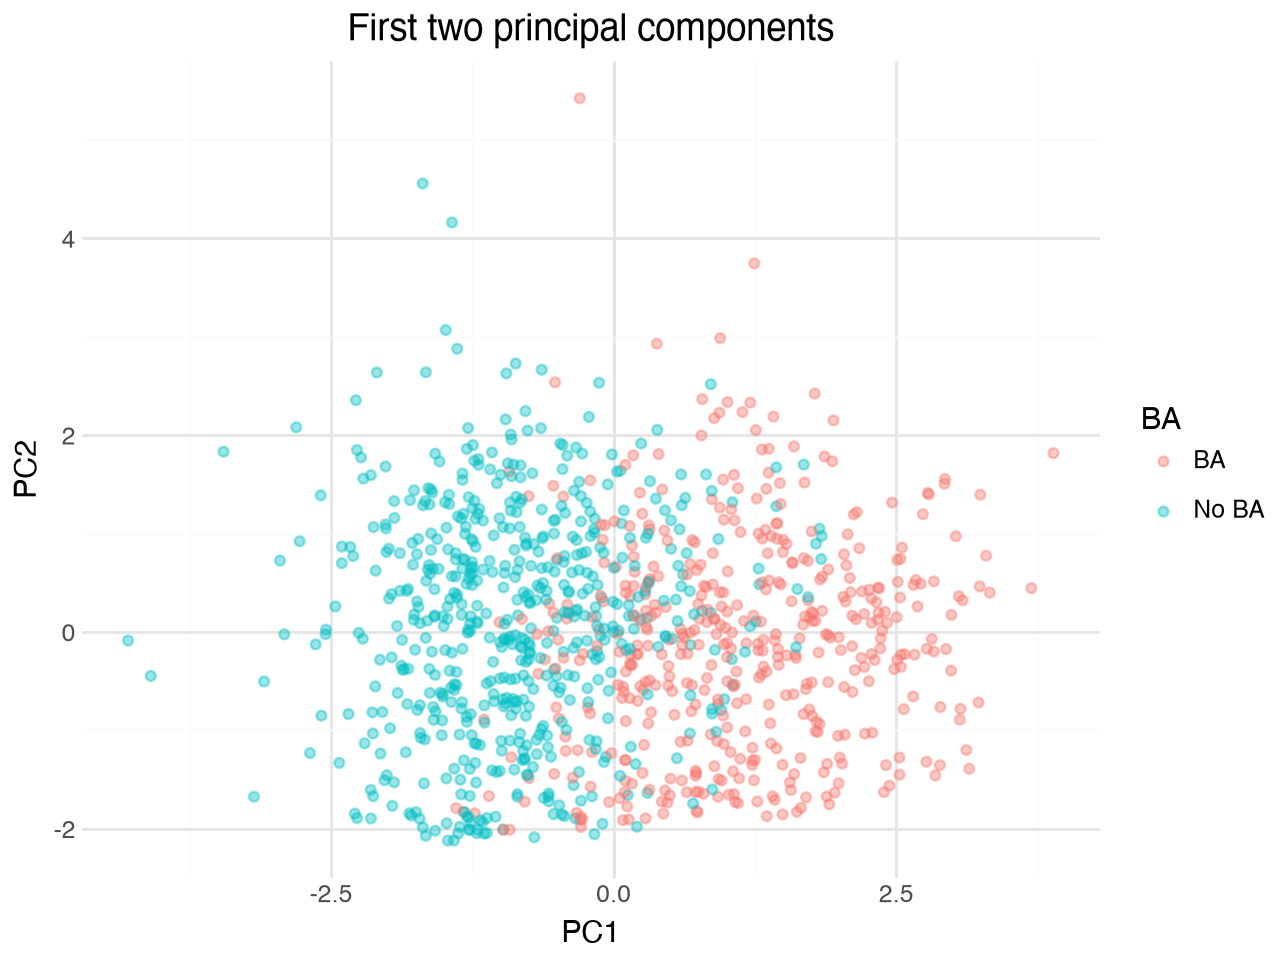

In [9]:
scores = pca.transform(X)
plot_df = work.copy()
plot_df["PC1"] = scores[:, 0]
plot_df["PC2"] = scores[:, 1]
plot_df["BA"] = np.where(plot_df["ba_binary"] == 1, "BA", "No BA")

(
    ggplot(plot_df, aes("PC1", "PC2", color="BA"))
    + geom_point(alpha=0.4, size=1.5)
    + theme_minimal()
    + labs(x="PC1", y="PC2", title="First two principal components")
)


## 7. A linear model for PC1

PC1 is the dependent variable. `ba_binary` is the independent variable: 1 is a BA, 0 is not.

This is an OLS model. The coefficient on `ba_binary` is the expected difference in PC1 between a person with a BA and a person without one.


In [10]:
import statsmodels.formula.api as smf

ols_model = smf.ols("PC1 ~ ba_binary", data=plot_df).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    PC1   R-squared:                       0.508
Model:                            OLS   Adj. R-squared:                  0.508
Method:                 Least Squares   F-statistic:                     1090.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):          9.80e-165
Time:                        12:14:12   Log-Likelihood:                -1453.9
No. Observations:                1056   AIC:                             2912.
Df Residuals:                    1054   BIC:                             2922.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.8650      0.039    -21.911      0.0

The intercept is -0.865. This shows that respondents without a BA tend to have a lower than average PC1 score. This makes snese because PC1 includes 3 components, income, education and prestige. The coefficient is 1.964. This means, on average, respondents with a BA score about 1.964 higher on PC1.

## 8. A logit model for a BA

`ba_binary` is now the dependent variable, and PC1 and PC2 are the independent variables. `ba_binary` is coded 0 or 1, so we fit a logit.

The coefficient is the expected change in the log odds of having a BA. Exponentiating it gives the factor by which the odds change.


In [12]:
logit_model = smf.logit("ba_binary ~ PC1 + PC2", data=plot_df).fit()
print(logit_model.summary())

print(np.exp(logit_model.params))

Optimization terminated successfully.
         Current function value: 0.340435
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              ba_binary   No. Observations:                 1056
Model:                          Logit   Df Residuals:                     1053
Method:                           MLE   Df Model:                            2
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.5037
Time:                        12:27:25   Log-Likelihood:                -359.50
converged:                       True   LL-Null:                       -724.43
Covariance Type:            nonrobust   LLR p-value:                3.259e-159
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.3769      0.095     -3.972      0.000      -0.563      -0.191
PC1            2.0936      0.

For PC1, the sign is positive, hence higher SES predicts a higher chance of having a BA. 

For PC2, the sign is negative, a further life stage predicts a lower chance of having a BA.

The odds ratio are printed below the OLS table. It shows that with every one point increase in PC2 multiplies the odds by 0.67, keeping PC1 constant. With every one point increase in PC1 multiplies the odds of having a BA by 8.11, keeping PC2 constant.

# Independent exercise

Use `happy_bin` as the dependent variable. Build the components from `income_cont`, `prestg10`, `educ`, `age`, and the four cultural-participation indicators (`binary_lvmus`, `binary_artxbt`, `binary_movie`, `binary_creat`). Leave `happy_bin` out of the PCA.

1. Scale each variable to mean 0 and SD 1, then fit a PCA.
2. Print the proportion of variance and the cumulative proportion.
3. Draw a scree plot with `plotnine` and decide how many components to keep.
4. Print the loadings and describe the first two components.
5. Scatter PC1 against PC2, coloured by happiness.
6. Fit a logit of `happy_bin` on the components you kept, and interpret the coefficients.


In [15]:
ex_cols = ["income_cont", "prestg10", "educ", "age",
           "binary_lvmus", "binary_artxbt", "binary_movie", "binary_creat"]

raw_culture = ["yrlvmus", "yrartxbt", "yrmovie", "yrcreat"]

#dropping those that have no values in culture questions
ex_work = df.dropna(subset=ex_cols + raw_culture + ["happy"]).copy()
print(len(ex_work)) #to check that people who didnt answer are not still in the data


ex_X = StandardScaler().fit_transform(ex_work[ex_cols])
ex_pca = PCA().fit(ex_X)

710


In [16]:
ex_prop = ex_pca.explained_variance_ratio_

print(pd.DataFrame({
    "Standard deviation": ex_pca.explained_variance_ ** 0.5,
    "Proportion of variance": ex_prop,
    "Cumulative proportion": ex_prop.cumsum(),
}, index=["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7", "PC8"]).T.round(3))

                          PC1    PC2    PC3    PC4    PC5    PC6    PC7    PC8
Standard deviation      1.472  1.235  1.044  0.944  0.832  0.776  0.756  0.686
Proportion of variance  0.271  0.191  0.136  0.111  0.086  0.075  0.071  0.059
Cumulative proportion   0.271  0.461  0.597  0.708  0.795  0.870  0.941  1.000


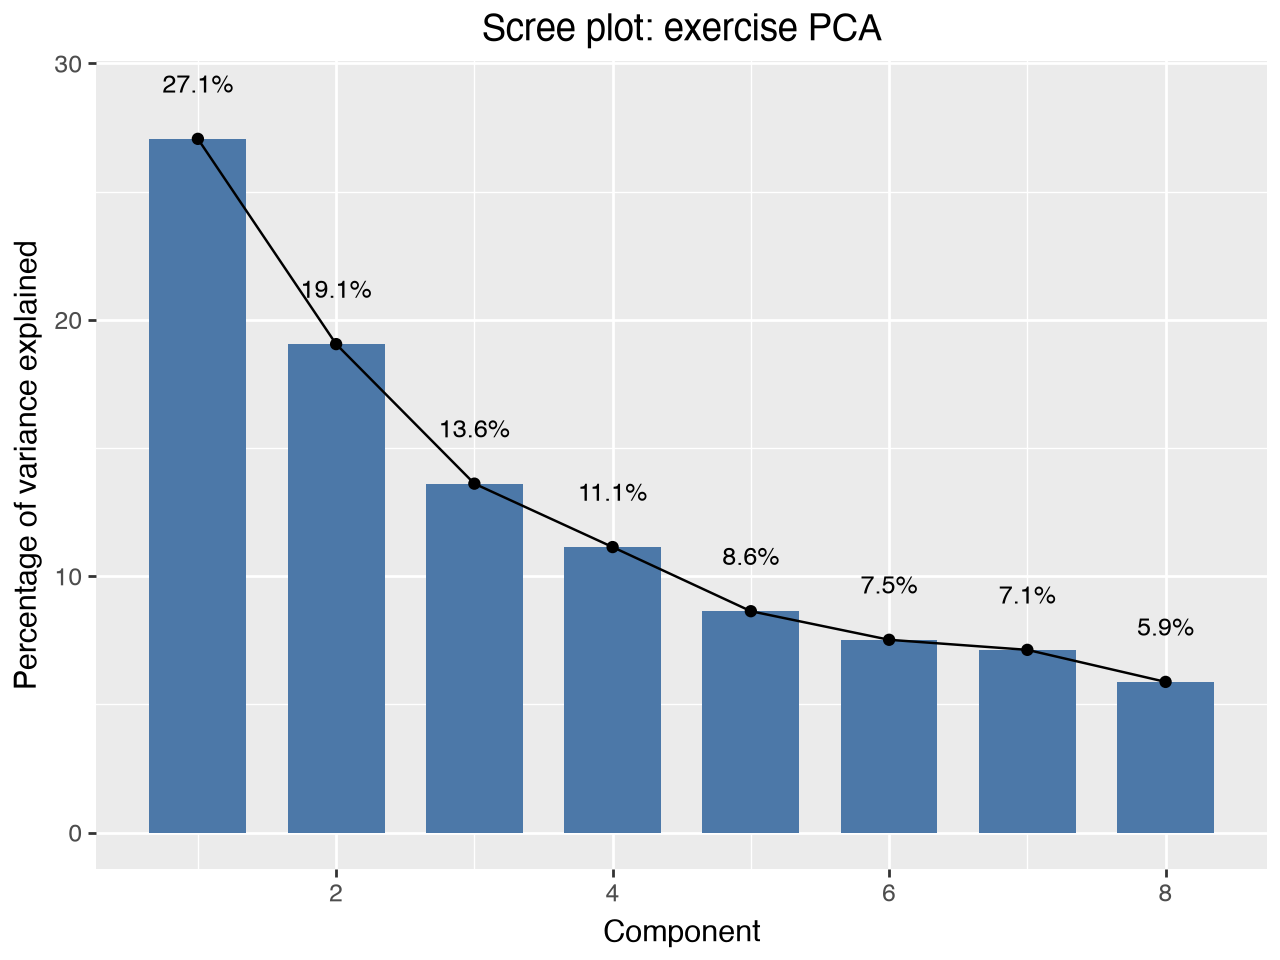

In [17]:
ex_scree = pd.DataFrame({
    "component": range(1, 9),
    "percent": ex_pca.explained_variance_ratio_ * 100,
})
ex_scree["label"] = ex_scree["percent"].map(lambda p: f"{p:.1f}%")

(
    ggplot(ex_scree, aes("component", "percent"))
    + geom_col(fill="#4C78A8", width=0.7)
    + geom_line(aes(group=1))
    + geom_point()
    + geom_text(aes(label="label"), nudge_y=1.6, size=9, va="bottom")
    + labs(x="Component", y="Percentage of variance explained",
           title="Scree plot: exercise PCA")
)

In [18]:
ex_loadings = pd.DataFrame(
    ex_pca.components_.T,
    index=ex_cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5", "PC6", "PC7", "PC8"],
)
print(ex_loadings[["PC1", "PC2", "PC3"]].round(3))

                 PC1    PC2    PC3
income_cont    0.425  0.327  0.178
prestg10       0.436  0.406 -0.057
educ           0.484  0.264 -0.098
age           -0.113  0.435 -0.381
binary_lvmus   0.393 -0.313  0.033
binary_artxbt  0.350 -0.339 -0.370
binary_movie   0.281 -0.319  0.581
binary_creat   0.161 -0.392 -0.579


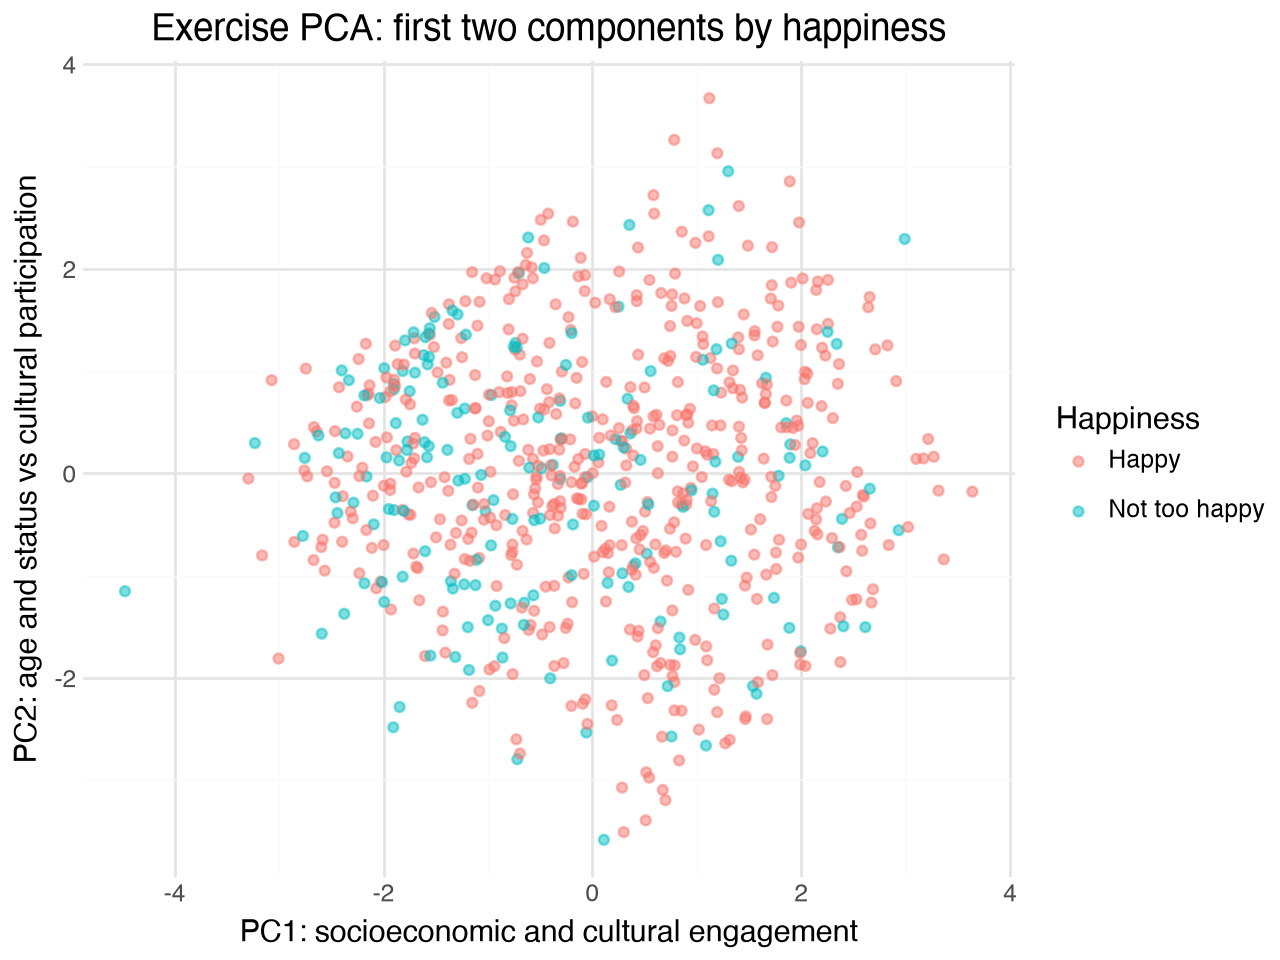

In [19]:
ex_scores = ex_pca.transform(ex_X)

ex_plot = ex_work.copy()
ex_plot["PC1"] = ex_scores[:, 0]
ex_plot["PC2"] = ex_scores[:, 1]
ex_plot["PC3"] = ex_scores[:, 2]
ex_plot["Happiness"] = np.where(ex_plot["happy_bin"] == 1, "Happy", "Not too happy")

(
    ggplot(ex_plot, aes("PC1", "PC2", color="Happiness"))
    + geom_point(alpha=0.5, size=1.5)
    + theme_minimal()
    + labs(x="PC1: socioeconomic and cultural engagement",
           y="PC2: age and status vs cultural participation",
           title="Exercise PCA: first two components by happiness")
)

In [20]:
import statsmodels.formula.api as smf

ex_logit = smf.logit("happy_bin ~ PC1 + PC2 + PC3", data=ex_plot).fit()
print(ex_logit.summary())

print(np.exp(ex_logit.params))

Optimization terminated successfully.
         Current function value: 0.540639
         Iterations 5
                           Logit Regression Results                           
Dep. Variable:              happy_bin   No. Observations:                  710
Model:                          Logit   Df Residuals:                      706
Method:                           MLE   Df Model:                            3
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                 0.03726
Time:                        12:56:47   Log-Likelihood:                -383.85
converged:                       True   LL-Null:                       -398.71
Covariance Type:            nonrobust   LLR p-value:                 1.590e-06
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.1614      0.091     12.726      0.000       0.983       1.340
PC1            0.2974      0.

#Interpretation

PC1 is positively associated with happiness. Every one unit increase in socioeconomic and cultural engagement mulitiplies the odds of being happy about 0.35. PC1 is significant as p-value is 0.000. 

PC2 is not signigicant as p-value is 0.144. 

PC3 is marginally significant.

WHile the model is significant overall, pseudo R quare = 0.037 which is very low, meaning the explanatory power is low. This could be because the variables included do not directly measure happiness. 